# Assignment No. 4: Machine Learning Model Application & Evaluation

**Student:** MUHAMMAD ZOHAIB  
**Roll No.:** 011  
**Section:** BSCS 3A  

## Project: Air Quality Measurements — Temperature Prediction

### Objective
Use the provided real-world-style air quality dataset to train and compare regression models that predict recorded **Temperature** from measured air pollutants and greenhouse-gas indicators.

### Problem definition
- **Problem type:** Regression, because the target is a continuous numeric value.
- **Target (y):** `Temperature`
- **Features (X):** `PM2.5`, `PM10`, `NOx`, `NO2`, `SO2`, `VOCs`, `CO`, `CO2`, and `CH4`.
- **Dataset:** The user-provided `air_quality_dataset.csv` containing 500 rows and 10 numeric columns.
- **Models:** Linear Regression, Decision Tree Regressor, Random Forest Regressor.
- **Metrics:** MAE, RMSE, and R².

**Scope note:** The file does not contain an explicit Air Quality Index (AQI) or pollution-category target. Therefore, this project does not invent a classification label; it uses the existing numeric `Temperature` column for a regression task. Predictive association does not imply that pollutants cause temperature changes.


In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 1. Load and inspect the dataset

Place `air_quality_dataset.csv` in the same folder as this notebook. If it is not present, the cell also supports uploading the original ZIP file in Google Colab.

In [2]:
csv_path = "air_quality_dataset.csv"

if not os.path.exists(csv_path):
    if os.path.exists("archive.zip"):
        with zipfile.ZipFile("archive.zip") as z:
            csv_name = next(n for n in z.namelist() if n.endswith("air_quality_dataset.csv"))
            with z.open(csv_name) as f:
                df = pd.read_csv(f)
    else:
        try:
            from google.colab import files
            uploaded = files.upload()
            if "air_quality_dataset.csv" in uploaded:
                df = pd.read_csv("air_quality_dataset.csv")
            else:
                zip_file = next((name for name in uploaded if name.lower().endswith(".zip")), None)
                if zip_file:
                    with zipfile.ZipFile(zip_file) as z:
                        csv_name = next(n for n in z.namelist() if n.endswith("air_quality_dataset.csv"))
                        with z.open(csv_name) as f:
                            df = pd.read_csv(f)
                else:
                    raise FileNotFoundError("Please upload air_quality_dataset.csv or archive.zip")
        except ImportError:
            raise FileNotFoundError("Put air_quality_dataset.csv beside this notebook.")

else:
    df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nMissing values per column:")
display(df.isna().sum().to_frame("Missing values"))
display(df.head())


Dataset shape: (500, 10)

Column names: ['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']

Missing values per column:


,Missing values
PM2.5,0
PM10,0
NOx,0
NO2,0
SO2,0
VOCs,0
CO,0
CO2,0
CH4,0
Temperature,0


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


## 2. Define features (X) and target (y)

We use the nine pollutant/gas columns as input features and predict `Temperature`. The target is removed from X to avoid target leakage.

In [3]:
target = "Temperature"
X = df.drop(columns=[target])
y = df[target]

print("Number of input features:", X.shape[1])
print("Feature columns:", X.columns.tolist())
print("Target:", target)
print("\nTarget summary:")
display(y.describe().to_frame("Temperature"))


Number of input features: 9
Feature columns: ['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4']
Target: Temperature

Target summary:


,Temperature
count,500.000000
mean,30.448413
std,2.957290
min,19.581349
25%,28.481974
50%,30.432756
75%,32.614954
max,39.778713


## 3. Train-test split

An 80/20 split is used. Models learn only from the training set; final metrics are calculated on the unseen test set. Preprocessing is kept inside each pipeline.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 400
Testing rows: 100


## 4. Train three regression models

- **Linear Regression:** baseline model for a linear relationship.
- **Decision Tree Regressor:** can model non-linear patterns and is limited to depth 5 to reduce overfitting.
- **Random Forest Regressor:** combines many trees to improve stability.

The median imputer handles any missing numeric values. Scaling is included for Linear Regression; the same pipeline structure keeps processing reproducible.

In [5]:
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Decision Tree Regressor": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(
            max_depth=5, min_samples_leaf=3, random_state=42
        ))
    ]),
    "Random Forest Regressor": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=2,
            random_state=42, n_jobs=-1
        ))
    ])
}

fitted_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    print(name, "trained successfully")


Linear Regression trained successfully
Decision Tree Regressor trained successfully


Random Forest Regressor trained successfully


## 5. Evaluate the models on the test set

- **MAE:** average absolute prediction error; lower is better.
- **RMSE:** penalizes larger errors more strongly; lower is better.
- **R²:** indicates how much target variation is explained relative to predicting the test-set mean; higher is better. A negative R² means the model performs worse than that simple baseline on this test set.

We will use **test RMSE as the primary metric**, while also checking MAE and R².

In [6]:
results = []
test_predictions = {}
for name, model in fitted_models.items():
    pred = model.predict(X_test)
    test_predictions[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R²": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(4))


,Model,MAE,RMSE,R²
0,Linear Regression,1.6325,2.0556,0.4682
1,Decision Tree Regressor,1.6768,2.0736,0.4589
2,Random Forest Regressor,1.6730,2.1341,0.4268


## 6. Compare actual and predicted values

The plot compares predictions with actual test-set temperatures. Points closer to the diagonal line indicate more accurate predictions.

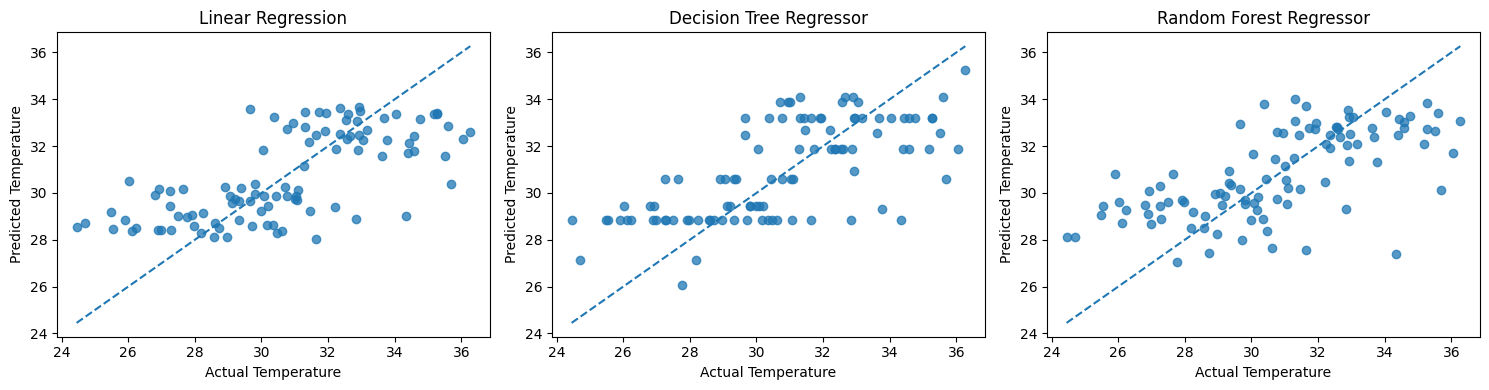

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, test_predictions.items()):
    ax.scatter(y_test, pred, alpha=0.75)
    low = min(float(y_test.min()), float(np.min(pred)))
    high = max(float(y_test.max()), float(np.max(pred)))
    ax.plot([low, high], [low, high], linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual Temperature")
    ax.set_ylabel("Predicted Temperature")
plt.tight_layout()
plt.show()


## 7. Check for overfitting or underfitting

We compare training and test MAE/RMSE/R². A very high training R² combined with much lower test R² can indicate overfitting. Low training and test R² together may indicate underfitting. The train-test gap is a diagnostic, not a perfect rule.

In [8]:
fit_rows = []
for name, model in fitted_models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)
    fit_rows.append({
        "Model": name,
        "Train R²": train_r2,
        "Test R²": test_r2,
        "Train-Test R² Gap": train_r2 - test_r2,
        "Train RMSE": mean_squared_error(y_train, train_pred) ** 0.5,
        "Test RMSE": mean_squared_error(y_test, test_pred) ** 0.5
    })

fit_df = pd.DataFrame(fit_rows).sort_values("Test RMSE")
display(fit_df.round(4))


,Model,Train R²,Test R²,Train-Test R² Gap,Train RMSE,Test RMSE
0,Linear Regression,0.3534,0.4682,-0.1148,2.3987,2.0556
1,Decision Tree Regressor,0.5361,0.4589,0.0772,2.0318,2.0736
2,Random Forest Regressor,0.8547,0.4268,0.4279,1.1371,2.1341


## 8. Final conclusion (generated from measured results)

The following cell chooses the model with the lowest test RMSE. It also reports MAE and R² and provides a cautious fit assessment based on the train-test R² gap.

In [9]:
best = results_df.iloc[0]
best_name = best["Model"]
fit_best = fit_df.loc[fit_df["Model"] == best_name].iloc[0]

print("BEST MODEL BY TEST RMSE:", best_name)
print(f"Test MAE:  {best['MAE']:.4f}")
print(f"Test RMSE: {best['RMSE']:.4f}")
print(f"Test R²:   {best['R²']:.4f}")
print()
print("Why RMSE was selected:")
print("RMSE is expressed in the target's units and gives larger errors extra weight.")
print("MAE is also reported because it is easy to interpret as the average absolute error.")
print()
gap = fit_best["Train-Test R² Gap"]
if gap > 0.20:
    fit_comment = "The training R² is substantially higher than test R², suggesting possible overfitting."
elif fit_best["Train R²"] < 0.20 and fit_best["Test R²"] < 0.20:
    fit_comment = "Both training and test R² are low, suggesting possible underfitting or weak predictive signal."
else:
    fit_comment = "The train-test scores do not show a large R² gap under this simple check; inspect both scores and consider cross-validation."
print("Fit assessment:", fit_comment)
print()
print("Conclusion:")
print(f"{best_name} performed best on this particular 20% test split according to the lowest RMSE.")
print("This conclusion is limited to this dataset and random split. The dataset contains no timestamp, location, or explicit AQI label.")
print("These models show predictive associations only; they do not establish that air pollutants cause temperature changes.")


BEST MODEL BY TEST RMSE: Linear Regression
Test MAE:  1.6325
Test RMSE: 2.0556
Test R²:   0.4682

Why RMSE was selected:
RMSE is expressed in the target's units and gives larger errors extra weight.
MAE is also reported because it is easy to interpret as the average absolute error.

Fit assessment: The train-test scores do not show a large R² gap under this simple check; inspect both scores and consider cross-validation.

Conclusion:
Linear Regression performed best on this particular 20% test split according to the lowest RMSE.
This conclusion is limited to this dataset and random split. The dataset contains no timestamp, location, or explicit AQI label.
These models show predictive associations only; they do not establish that air pollutants cause temperature changes.


## 9. Limitations

1. The dataset has 500 rows and may not represent all locations, seasons, or monitoring conditions.
2. The provided data contains no date/time or location columns, so temporal and geographic generalization cannot be evaluated.
3. Temperature is a numeric target available in the file, but predicting it from pollutant measurements may have limited practical value; results should be interpreted as a modelling exercise.
4. A future extension could use a validated AQI label or timestamp-based forecasting dataset, if available.
5. For stronger evaluation, use cross-validation and a separately collected external test dataset.

## Dataset used
User-provided file: `air_quality_dataset.csv` (distributed in the uploaded `archive.zip`).